# Digit Recognizer with PyTorch

**Author:** Estelle Arnander · **Kaggle username:** estellearnander03

**Objective:** classify 28 x 28 grayscale handwritten digits (0 to 9) from the Kaggle Digit Recognizer competition.
We train an MLP baseline, a convolutional neural network (CNN) and improved CNNs, compare them on a hold-out
validation set and submit the best predictions to Kaggle.

All reusable code lives in the `digit_recognizer` package (`src/digit_recognizer/`). This notebook only imports it,
runs the experiments and shows the results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from digit_recognizer import (
    DigitDataset,
    check_data,
    compute_mean_std,
    get_device,
    load_test,
    load_train,
    make_loaders,
    set_seed,
    split_train_val,
)

SEED = 42
set_seed(SEED)
device = get_device()
print("Device:", device)

Device: mps


## 1. Data

### 1.1 Paths

The project root is the folder that contains `pyproject.toml`. Depending on the editor, the notebook runs either
from `notebooks/` or from the project root, so we check both.

In [2]:
if (Path.cwd() / "pyproject.toml").exists():
    project_root = Path.cwd()
else:
    project_root = Path.cwd().parents[0]

data_dir = project_root / "data"
results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)
print("Project root:", project_root)

Project root: /Users/estellearnander/sem5/AI/digit-recognizer


### 1.2 Load and check the data

`check_data` confirms the expected shapes (42,000 x 785 and 28,000 x 784), that `label` is the first column,
that labels are 0 to 9, that pixels are 0 to 255 and that there are no missing values.

In [3]:
train_df = load_train(data_dir / "train.csv")
test_df = load_test(data_dir / "test.csv")

print("train.csv:", train_df.shape)
print("test.csv: ", test_df.shape)
print("Checks passed:", check_data(train_df, test_df))
train_df.iloc[:5, :8]

train.csv: (42000, 785)
test.csv:  (28000, 784)
Checks passed: True


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6
0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0


### 1.3 Train / validation split and normalisation

We keep a stratified 90/10 hold-out split with a fixed seed, so every model is evaluated on exactly the same
4,200 validation images and each class keeps the same proportion in both parts.

Pixels are scaled to [0, 1] and then normalised with the mean and standard deviation of the **training split only**.
Computing them on all the data would let validation information leak into preprocessing.

In [4]:
X_train, X_val, y_train, y_val = split_train_val(train_df, val_size=0.1, seed=SEED)
mean, std = compute_mean_std(X_train)

print("Training images:  ", X_train.shape[0])
print("Validation images:", X_val.shape[0])
print(f"Training mean = {mean:.4f}, std = {std:.4f}")

Training images:   37800
Validation images: 4200
Training mean = 0.1310, std = 0.3085


### 1.4 Dataset and DataLoader

`DigitDataset` reshapes each row of 784 pixels to an image of shape `[1, 28, 28]` (1 channel, height, width).
The DataLoader groups images into batches of shape `[B, 1, 28, 28]`, the format a PyTorch CNN expects.

In [5]:
train_ds = DigitDataset(X_train, y_train, mean, std)
val_ds = DigitDataset(X_val, y_val, mean, std)
train_loader, val_loader = make_loaders(train_ds, val_ds, batch_size=128, seed=SEED)

images, labels = next(iter(train_loader))
print("Image batch:", tuple(images.shape), images.dtype)
print("Label batch:", tuple(labels.shape), labels.dtype)
print(f"Pixel values after normalisation: min {images.min():.2f}, max {images.max():.2f}")

Image batch: (128, 1, 28, 28) torch.float32
Label batch: (128,) torch.int64
Pixel values after normalisation: min -0.42, max 2.82


### 1.5 Look at the data

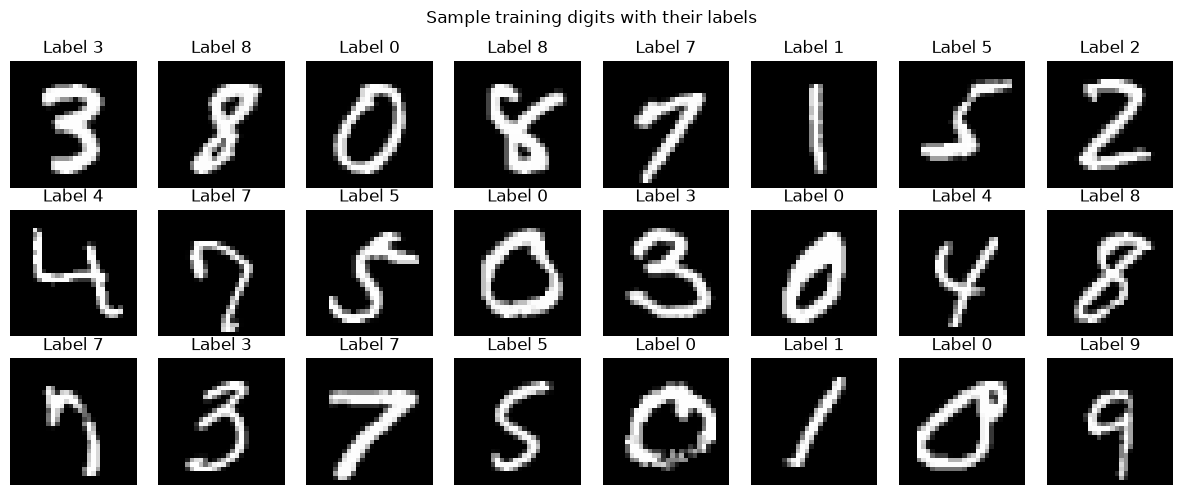

In [6]:
fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for ax, i in zip(axes.flat, range(24)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label {y_train[i]}")
    ax.axis("off")
fig.suptitle("Sample training digits with their labels")
plt.tight_layout()
plt.savefig(results_dir / "sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

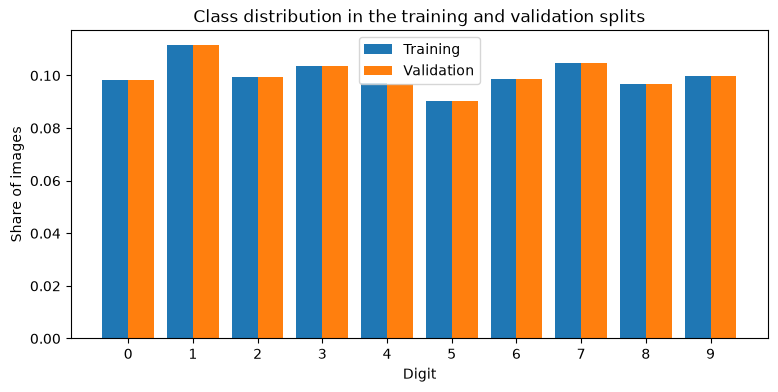

Training counts:   [3719 4216 3759 3916 3665 3415 3723 3961 3657 3769]
Validation counts: [413 468 418 435 407 380 414 440 406 419]


In [7]:
classes = np.arange(10)
train_counts = np.bincount(y_train, minlength=10)
val_counts = np.bincount(y_val, minlength=10)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(classes - 0.2, train_counts / train_counts.sum(), width=0.4, label="Training")
ax.bar(classes + 0.2, val_counts / val_counts.sum(), width=0.4, label="Validation")
ax.set_xticks(classes)
ax.set_xlabel("Digit")
ax.set_ylabel("Share of images")
ax.set_title("Class distribution in the training and validation splits")
ax.legend()
plt.savefig(results_dir / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Training counts:  ", train_counts)
print("Validation counts:", val_counts)

**Observations**

- Stratification works: every digit has the same share of images in the training and validation splits.
- The classes are roughly balanced. The most common digit (1, with 4,216 training images) appears about
  1.2 times as often as the least common (5, with 3,415). With an imbalance this mild, accuracy is a fair
  metric (it is also the Kaggle metric) and no class weighting is needed in the loss.
- After normalisation the black background has the value -0.42 and the brightest strokes 2.82.